# Train-Delay Prediction Reliability - Visual Analysis

Exploratory visuals for the RIDE Gold Lite reliability pipeline. Run the pipeline first:

```
python src/prepare_data.py
python src/module1_accuracy.py
python src/module2_uncertainty.py
python src/module3_drift.py
python src/module4_scenarios.py
```

This notebook consumes the saved predictions and tables; it does not retrain anything.
All quantities are in physical units (seconds of delay change, minutes of horizon).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import (
    PREDICTIONS_DIR,
    REPORTS_DIR,
    coverage,
    horizon_bin,
    load_split,
    mean_width,
)

pred = pd.read_parquet(PREDICTIONS_DIR / "test_interval_predictions.parquet")
tables = pd.read_csv(PREDICTIONS_DIR / "conditional_reliability_tables.csv")
scenarios = pd.read_csv(REPORTS_DIR / "decision_scenarios.csv")
print(f"{len(pred):,} test predictions loaded ({pred['month'].min()} .. {pred['month'].max()})")

2,094,765 test predictions loaded (2025-01 .. 2025-12)


## 1. What does the prediction target look like?

The target is the *change* in a train's delay between the prediction snapshot and a future
scheduled event, in seconds. Most changes are near zero, but the tails are long - exactly the
situation where an "accurate on average" model can be misleading.

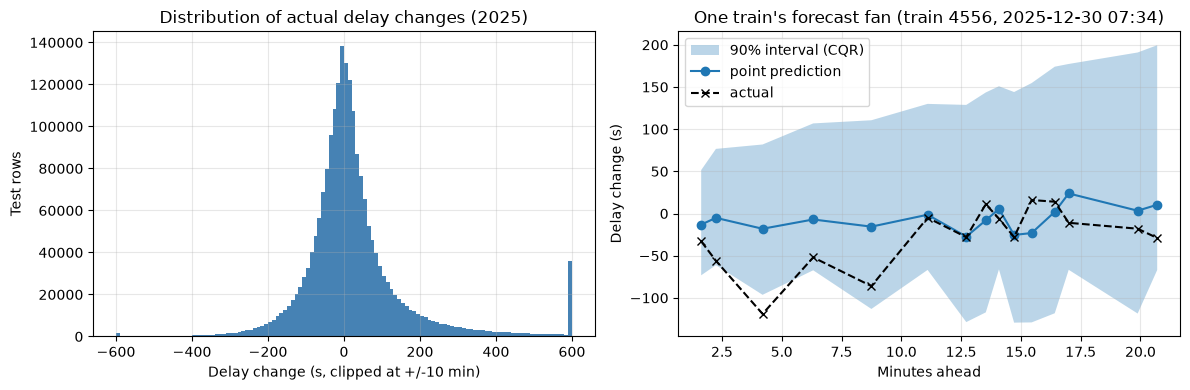

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pred["y_delta_sec"].clip(-600, 600), bins=120, color="steelblue")
axes[0].set_xlabel("Delay change (s, clipped at +/-10 min)")
axes[0].set_ylabel("Test rows")
axes[0].set_title("Distribution of actual delay changes (2025)")

sample = pred.groupby(["snapshot_ts", "train_id"], observed=True).size()
key = sample[sample >= 14].sample(1, random_state=7).index[0]
traj = pred[(pred["snapshot_ts"] == key[0]) & (pred["train_id"] == key[1])].sort_values("horizon_step")
axes[1].fill_between(traj["obs_horizon_min"], traj["cqr_lower_90"], traj["cqr_upper_90"],
                     alpha=0.3, label="90% interval (CQR)")
axes[1].plot(traj["obs_horizon_min"], traj["y_pred"], "o-", label="point prediction")
axes[1].plot(traj["obs_horizon_min"], traj["y_delta_sec"], "kx--", label="actual")
axes[1].set_xlabel("Minutes ahead")
axes[1].set_ylabel("Delay change (s)")
axes[1].set_title(f"One train's forecast fan (train {key[1]}, {key[0]:%Y-%m-%d %H:%M})")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

## 2. Reliability diagram: does stated confidence match reality?

A 90% interval should contain the truth 90% of the time. Points below the diagonal mean the
model is **overconfident** (intervals too narrow); above means **underconfident** (too wide).

,method,nominal,empirical,mean_width_s
0,split,0.8,0.814873,225.571838
1,split,0.9,0.906405,363.109009
2,cqr,0.8,0.808016,245.604217
3,cqr,0.9,0.901472,351.191776


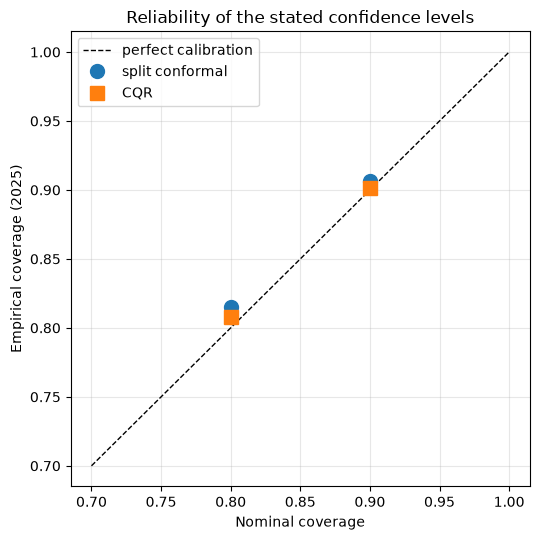

In [3]:
y = pred["y_delta_sec"]
rows = []
for method in ("split", "cqr"):
    for level in (80, 90):
        rows.append({
            "method": method,
            "nominal": level / 100,
            "empirical": coverage(y, pred[f"{method}_lower_{level}"], pred[f"{method}_upper_{level}"]),
            "mean_width_s": mean_width(pred[f"{method}_lower_{level}"], pred[f"{method}_upper_{level}"]),
        })
summary = pd.DataFrame(rows)
display(summary)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0.7, 1.0], [0.7, 1.0], "k--", lw=1, label="perfect calibration")
for method, marker in (("split", "o"), ("cqr", "s")):
    m = summary[summary["method"] == method]
    ax.plot(m["nominal"], m["empirical"], marker, ms=10,
            label={"split": "split conformal", "cqr": "CQR"}[method])
ax.set_xlabel("Nominal coverage")
ax.set_ylabel("Empirical coverage (2025)")
ax.set_title("Reliability of the stated confidence levels")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

## 3. Conditional reliability: horizon, operating regime, congestion, and drift

Marginal (average) coverage can hide failures in specific operating conditions. These tables and
plots come from `module3_drift.py` and slice the same 90% intervals four different ways.

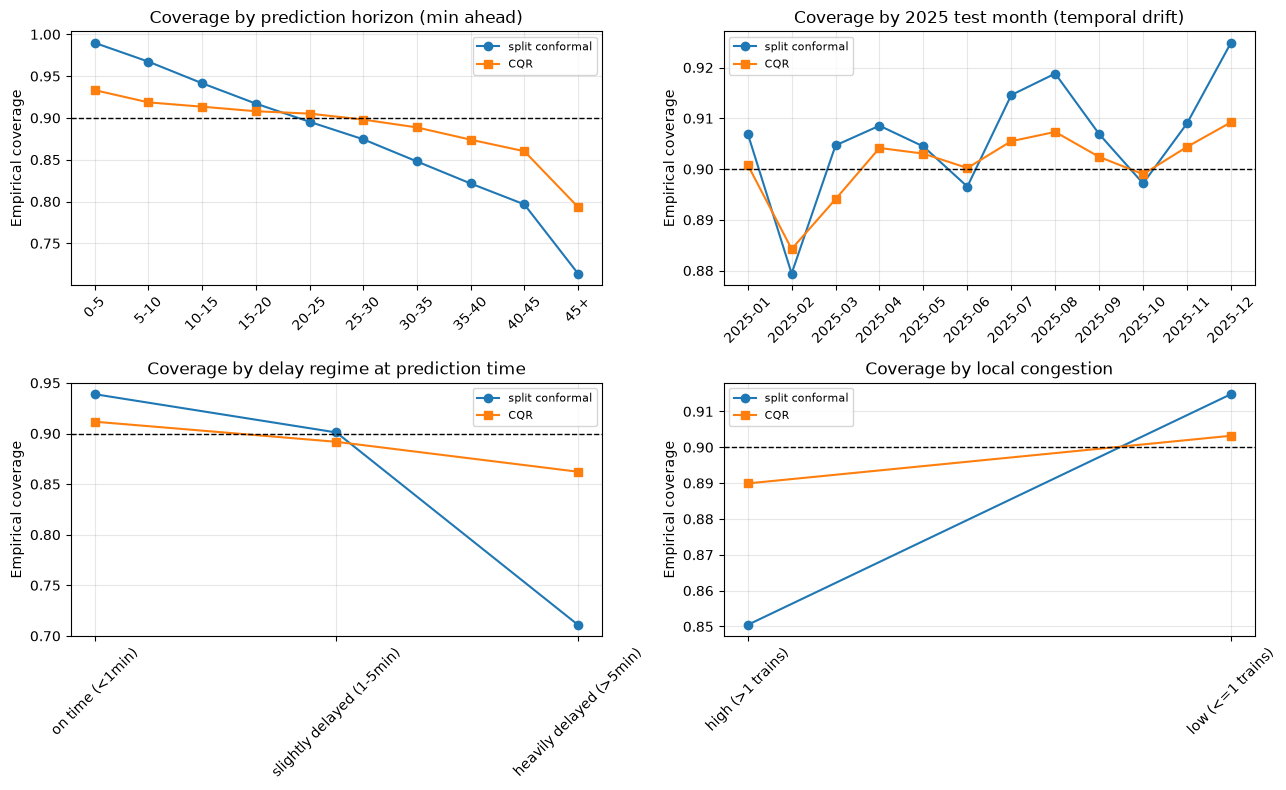

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
conditions = [
    ("horizon_bin", "Coverage by prediction horizon (min ahead)", axes[0, 0]),
    ("month", "Coverage by 2025 test month (temporal drift)", axes[0, 1]),
    ("delay_regime", "Coverage by delay regime at prediction time", axes[1, 0]),
    ("congestion_regime", "Coverage by local congestion", axes[1, 1]),
]
for cond, title, ax in conditions:
    for method, marker in (("split", "o"), ("cqr", "s")):
        t = tables[(tables["condition"] == cond) & (tables["method"] == method)]
        t = t.sort_values("group") if cond == "month" else t
        ax.plot(t["group"].astype(str), t["coverage"], marker + "-",
                label={"split": "split conformal", "cqr": "CQR"}[method])
    ax.axhline(0.9, color="k", ls="--", lw=1)
    ax.set_title(title)
    ax.set_ylabel("Empirical coverage")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()

## 4. Sharpness: constant-width vs adaptive intervals

Two methods with similar average coverage can distribute their uncertainty very differently.
Split conformal uses (nearly) one width everywhere; CQR widens where predictions are genuinely
harder. Width is the price paid for coverage - narrower at equal coverage is better ("sharper").

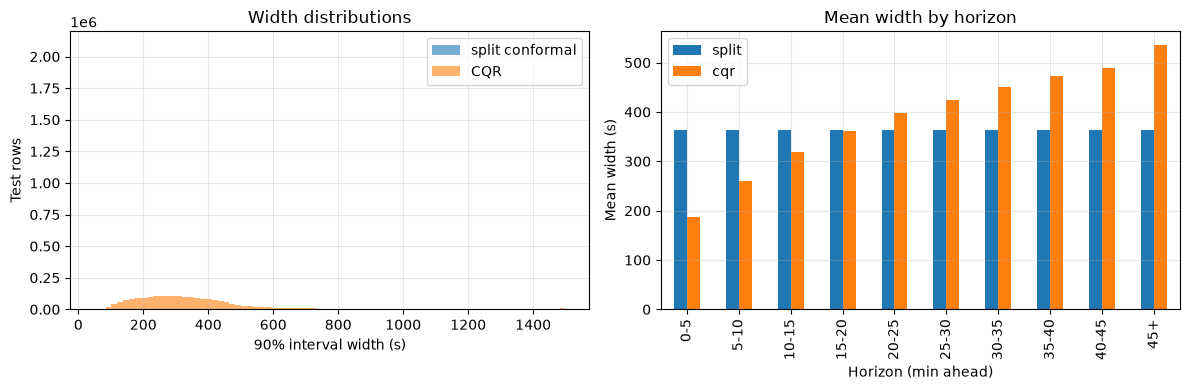

In [5]:
split_w = pred["split_upper_90"] - pred["split_lower_90"]
cqr_w = pred["cqr_upper_90"] - pred["cqr_lower_90"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(split_w.clip(0, 1500), bins=80, alpha=0.6, label="split conformal")
axes[0].hist(cqr_w.clip(0, 1500), bins=80, alpha=0.6, label="CQR")
axes[0].set_xlabel("90% interval width (s)")
axes[0].set_ylabel("Test rows")
axes[0].set_title("Width distributions")
axes[0].legend()

hb = horizon_bin(pred["obs_horizon_min"])
w_by_h = pd.DataFrame({"horizon": hb, "split": split_w, "cqr": cqr_w}).groupby(
    "horizon", observed=True).mean()
w_by_h.plot(kind="bar", ax=axes[1])
axes[1].set_xlabel("Horizon (min ahead)")
axes[1].set_ylabel("Mean width (s)")
axes[1].set_title("Mean width by horizon")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

## 5. Decision scenarios

Real 2025 test instances mined by `module4_scenarios.py`: accurate-but-uncertain predictions,
narrow-but-wrong intervals, disruption failures, and short- vs long-horizon pairs for the same train.

In [6]:
pd.set_option("display.max_columns", None)
display(scenarios)

,scenario,snapshot_ts,train_id,obs_horizon_min,last_known_delay_sec,y_pred,lower,upper,width,y_delta_sec,abs_error,inside_interval
0,A: accurate but uncertain,2025-10-11 08:44:19,9316,35.0,248.0,-124.0,-264.0,323.0,588.0,-112.0,12.0,True
1,A: accurate but uncertain,2025-05-08 15:03:57,9555,22.6,284.0,-56.0,-268.0,368.0,637.0,-70.0,14.0,True
2,A: accurate but uncertain,2025-03-03 18:25:27,19,21.8,27.0,138.0,-74.0,567.0,641.0,166.0,28.0,True
3,B: narrow but wrong,2025-01-13 15:25:34,2514,4.6,33.0,-26.0,-86.0,64.0,150.0,98.0,124.0,False
4,B: narrow but wrong,2025-02-21 17:05:48,5387,1.0,5.0,-21.0,-72.0,72.0,145.0,-75.0,54.0,False
5,B: narrow but wrong,2025-02-01 10:38:35,19826,0.2,44.0,-24.0,-59.0,47.0,106.0,-60.0,36.0,False
6,C: fails in disruption,2025-12-03 08:31:17,1907,39.0,611.0,-73.0,-327.0,415.0,743.0,723.0,796.0,False
7,C: fails in disruption,2025-10-28 20:15:32,9167,15.9,610.0,11.0,-120.0,388.0,509.0,436.0,425.0,False
8,C: fails in disruption,2025-04-30 20:50:28,3392,33.9,547.0,-123.0,-512.0,516.0,1028.0,-583.0,460.0,False
9,D: short horizon,2025-05-15 11:42:58,9528,0.1,90.0,-29.0,-37.0,64.0,101.0,-25.0,4.0,True
